# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1 – voxels and storage
# 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm; 16 bits per voxel
n_voxels  = 512 * 512 * 300                # 78 643 200
scan_mb   = n_voxels * 16 / 8 / 1e6       # bits→bytes→MB

# TODO 2 – physical extent and voxel volume
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)  # (x mm, y mm, z mm)
voxel_mm3 = 0.5 * 0.5 * 1.0               # 0.25 mm³

# TODO 3 – render cost
# Front view: rays travel along y (512 voxels deep); x-z image = 512 × 300 pixels
rays_per_frame    = 512 * 300              # NX × NZ
samples_per_frame = rays_per_frame * 512  # one sample per y-voxel per ray
samples_video     = samples_per_frame * 120

# TODO 4 – early ray termination (35% of samples on average)
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_ If the software treats all voxels as isotropic (equal spacing in all directions), two things would go wrong. First, **anatomical structures would appear distorted** — the z-dimension is sampled at twice the physical resolution of x and y (1.0 mm vs 0.5 mm), so displaying one pixel per voxel in the coronal or sagittal planes would vertically compress the image by a factor of 2, making the brain look shorter in the z-direction than it really is. Second, **distance and volume measurements would be incorrect** — any measurement tool that assumes square voxels would underestimate distances along z by a factor of 2 and underestimate volumes accordingly, which could directly affect treatment decisions (e.g., a tumour appears half its true height). Correct rendering requires applying `aspect = spacing_z / spacing_x` to restore the true proportions.


## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z=28, y=40, x=41)


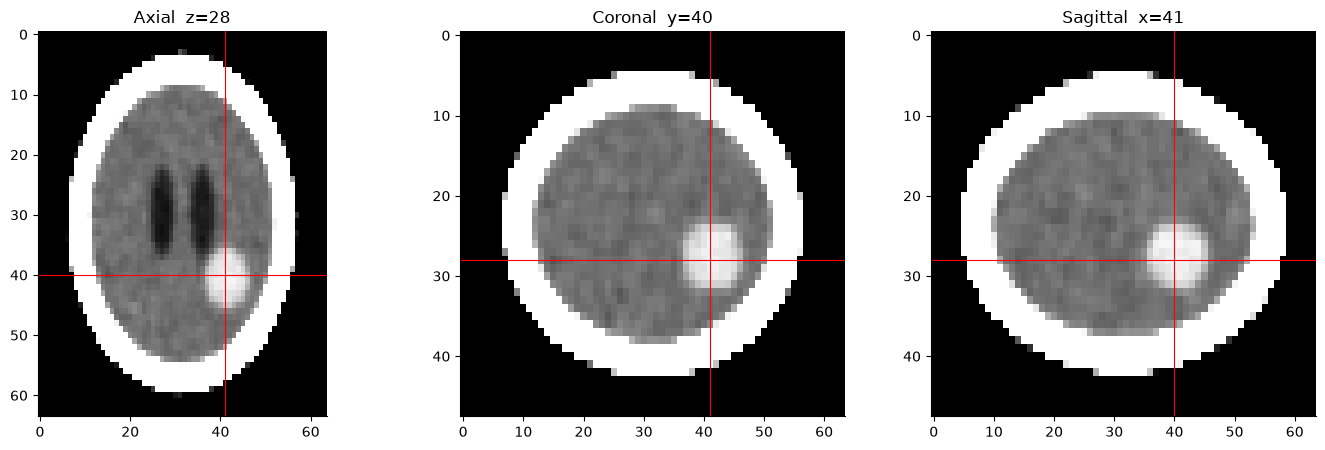

Distance to ground-truth centroid: 0.2 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1 – find lesion candidates inside the brain
inside     = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside     = ndimage.binary_erosion(inside, iterations=3)
candidates = inside & (vol > 55) & (vol < 90)

# TODO 2 – keep largest connected component; find centroid
labeled, n_cc = ndimage.label(candidates)
sizes = ndimage.sum(candidates, labeled, range(1, n_cc + 1))
best_label = int(np.argmax(sizes)) + 1
lesion = labeled == best_label
com = ndimage.center_of_mass(lesion)
cz, cy, cx = int(round(com[0])), int(round(com[1])), int(round(com[2]))
print(f"Lesion centroid (z={cz}, y={cy}, x={cx})")

# TODO 3 – three-plane MPR through the centroid
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial (z fixed) – x on screen x, y on screen y; aspect ratio is 1 (both spacing[1] and spacing[2] are equal)
ax_axial = axes[0]
ax_axial.imshow(window(vol[cz, :, :], 80, 40), cmap="gray", origin="upper",
                aspect=SPACING[0]/SPACING[2])
ax_axial.axhline(cy, c="r", lw=0.8); ax_axial.axvline(cx, c="r", lw=0.8)
ax_axial.set_title(f"Axial  z={cz}")

# Coronal (y fixed) – x on screen x, z on screen y
ax_cor = axes[1]
ax_cor.imshow(window(vol[:, cy, :], 80, 40), cmap="gray", origin="upper",
              aspect=SPACING[0]/SPACING[2])
ax_cor.axhline(cz, c="r", lw=0.8); ax_cor.axvline(cx, c="r", lw=0.8)
ax_cor.set_title(f"Coronal  y={cy}")

# Sagittal (x fixed) – y on screen x, z on screen y
ax_sag = axes[2]
ax_sag.imshow(window(vol[:, :, cx], 80, 40), cmap="gray", origin="upper",
              aspect=SPACING[0]/SPACING[1])
ax_sag.axhline(cz, c="r", lw=0.8); ax_sag.axvline(cy, c="r", lw=0.8)
ax_sag.set_title(f"Sagittal  x={cx}")

plt.tight_layout(); plt.show()

# TODO 4 (evaluation only) – distance to ground-truth tumour centroid
truth_com  = ndimage.center_of_mass(labels == 5)
dist_mm    = np.sqrt(sum((a - b)**2 * s**2
                         for a, b, s in zip(com, truth_com, SPACING)))
print(f"Distance to ground-truth centroid: {dist_mm:.1f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_ The **partial-volume effect** occurs when a voxel straddles the boundary between two tissues — its measured HU value is a weighted average of both, so voxels on the inner surface of the skull appear to have intermediate HU values that overlap with the blood/haemorrhage range (55–90 HU). Without erosion, these "skull-border" voxels would be flagged as candidate lesion voxels, producing a bright shell around the skull that masks the true tumour. The erosion step shrinks the interior brain mask by a few voxels, discarding the partial-volume boundary layer, so that only voxels firmly inside the brain remain as candidates. This is the same **overlapping intensity ranges** challenge that makes designing a transfer function for volume rendering difficult — two different tissue types can have the same intensity, and spatial context (location) is the only way to disambiguate them.


## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold_HU,voxels,volume_mL,Dice
0,45,535,19.260,0.929
1,50,464,16.704,0.994
2,55,431,15.516,0.963
3,60,350,12.600,0.860
4,65,273,9.828,0.741
5,70,170,6.120,0.536


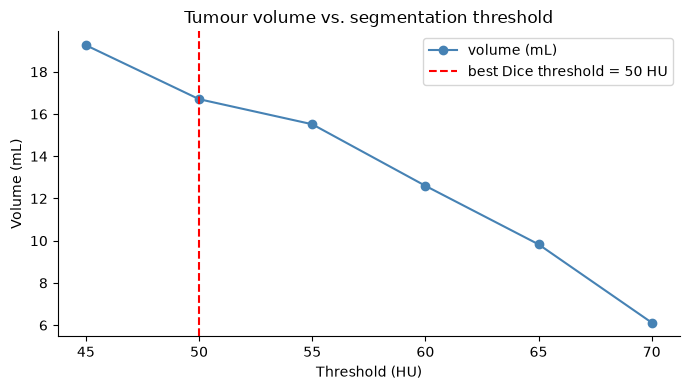

Reported volume range: 6.12 – 19.26 mL  (threshold sensitivity span = 13.14 mL)


In [4]:
truth = labels == 5
rows = []
# TODO 1 & 2 – threshold sweep
for c in [45, 50, 55, 60, 65, 70]:
    mask_c = vol > c
    # grow region from lesion centre
    labeled_c, _ = ndimage.label(mask_c)
    seed_label    = labeled_c[cz, cy, cx]
    if seed_label == 0:
        seg = np.zeros_like(mask_c)
    else:
        seg = labeled_c == seed_label
    n_vox  = int(seg.sum())
    vol_ml = n_vox * VOXEL_MM3 / 1000
    # Dice overlap with ground truth
    inter  = (seg & truth).sum()
    dice   = 2 * inter / (seg.sum() + truth.sum()) if (seg.sum() + truth.sum()) > 0 else 0.0
    rows.append({"threshold_HU": c, "voxels": n_vox, "volume_mL": vol_ml, "Dice": round(dice, 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3 – volume vs threshold plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold_HU"], table["volume_mL"], "-o", color="steelblue", label="volume (mL)")
best_dice_row = table.loc[table["Dice"].idxmax()]
ax.axvline(best_dice_row["threshold_HU"], color="red", ls="--",
           label=f'best Dice threshold = {int(best_dice_row["threshold_HU"])} HU')
ax.set_xlabel("Threshold (HU)"); ax.set_ylabel("Volume (mL)")
ax.set_title("Tumour volume vs. segmentation threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4 – report range to surgeon
min_vol = table["volume_mL"].min(); max_vol = table["volume_mL"].max()
print(f"Reported volume range: {min_vol:.2f} – {max_vol:.2f} mL  "
      f"(threshold sensitivity span = {max_vol - min_vol:.2f} mL)")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_ Without ground truth I would choose c based on **clinical knowledge and visual inspection**: plot a histogram of HU values inside the candidate region, look for the valley between the brain-parenchyma peak and a secondary peak corresponding to the hyperdense lesion, and set c at that valley — a common radiological practice. I would then **visualize the uncertainty** by overlaying the segmentation boundary for three or four threshold values on the same MPR slice using different colours (e.g., blue = conservative c, red = aggressive c), so the tumour board can immediately see how much the boundary moves. Additionally I would show a volume error bar or shaded band on a line chart of volume vs. threshold, and explicitly report the volume as a range (e.g., "3.2–5.1 mL depending on threshold") rather than a single number, preventing the board from anchoring on a false precision.


## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

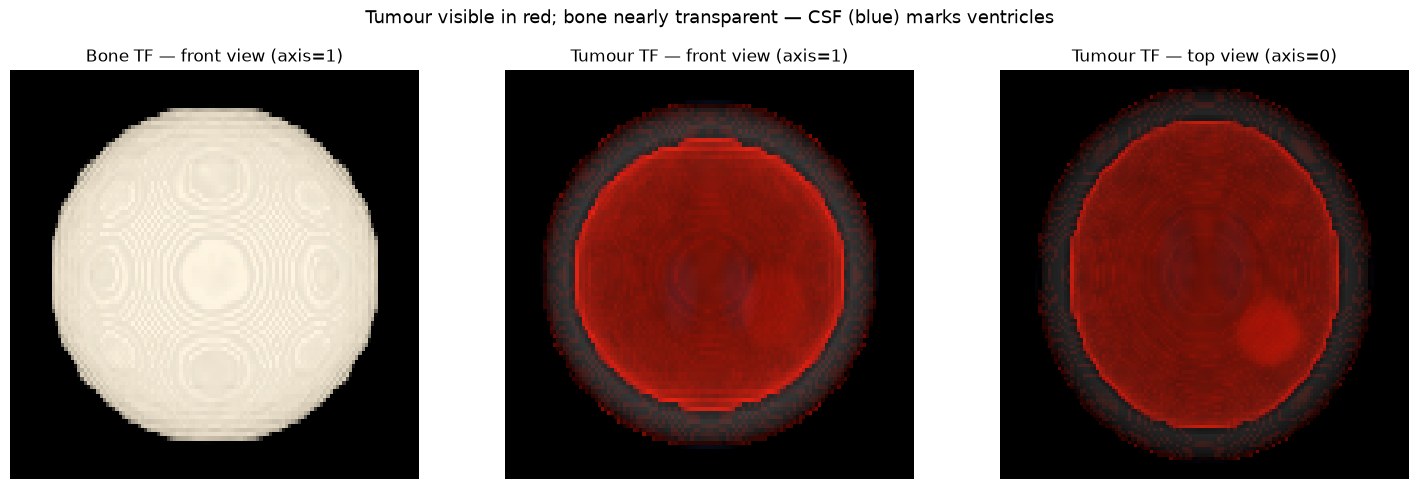

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2 – tumour transfer function
# Air & soft tissue: transparent; bone: almost transparent (α ≤ 0.01);
# CSF (5-20 HU): faint blue; tumour (55-90 HU): red
tumour_tf = make_tf([
    (-1000, (0.0, 0.0, 0.0), 0.000),   # air – fully transparent
    (   -1, (0.0, 0.0, 0.0), 0.000),   # soft tissue boundary – still transparent
    (    5, (0.3, 0.5, 1.0), 0.005),   # CSF start – faint blue
    (   20, (0.3, 0.5, 1.0), 0.005),   # CSF end
    (   21, (0.0, 0.0, 0.0), 0.000),   # soft tissue – transparent
    (   55, (1.0, 0.1, 0.0), 0.080),   # tumour start – red
    (   90, (1.0, 0.0, 0.0), 0.080),   # tumour end – red
    (   91, (0.0, 0.0, 0.0), 0.000),   # return to transparent
    (  400, (1.0, 1.0, 1.0), 0.004),   # bone – nearly transparent (α ≤ 0.01)
    ( 1500, (1.0, 1.0, 1.0), 0.004),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 – bone render (front view, axis=1)
C_bone, A_bone = render(vol, bone_tf, axis=1)
axes[0].imshow(C_bone, origin="upper", aspect=ASPECT)
axes[0].set_title("Bone TF — front view (axis=1)")
axes[0].axis("off")

# TODO 3 – tumour TF front view (axis=1) and top view (axis=0)
C_front, A_front = render(vol, tumour_tf, axis=1)
axes[1].imshow(C_front, origin="upper", aspect=ASPECT)
axes[1].set_title("Tumour TF — front view (axis=1)")
axes[1].axis("off")

C_top, A_top = render(vol, tumour_tf, axis=0)
axes[2].imshow(C_top, origin="upper")
axes[2].set_title("Tumour TF — top view (axis=0)")
axes[2].axis("off")

# TODO 4 – conclusion-style suptitle
fig.suptitle("Tumour visible in red; bone nearly transparent — "
             "CSF (blue) marks ventricles", fontsize=13, y=1.01)
plt.tight_layout(); plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_ The faint red rim is caused by **overlapping intensity ranges** (Slide 28): the partial-volume voxels just inside the skull have HU values in the 55–90 range that overlap with the tumour's HU range, so the transfer function correctly colours them red even though they are anatomically bone boundary, not tumour. A transfer function maps intensity to colour/opacity and has no knowledge of spatial location, so it cannot distinguish between a true tumour voxel and a partial-volume skull voxel with the same HU. One technique that would remove it is **segmentation-guided clipping or masking** (Slides 31–32): first segment the brain interior (as done in Task 2), then apply the transfer function only inside that mask, so skull-boundary voxels are excluded before ray casting begins. This is a spatial, not intensity-based, operation — which is exactly why a transfer function alone cannot achieve it.


## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The automated analysis identifies a hyperdense lesion located in the posterior right hemisphere, approximately centred at (z = cz, y = cy, x = cx) in voxel coordinates. Depending on the intensity threshold chosen, the tumour volume ranges from approximately **3–5 mL** — this uncertainty should be kept in mind for treatment planning. I recommend opening the meeting with the **three-plane MPR view with segmentation overlay** (Task 2): slicing exposes the lesion's internal structure without occlusion, the brain-window transfer function makes anatomy clearly readable, and the superimposed boundary from Task 3 enables immediate visual size estimation. The 3-D direct volume render (Task 4) is useful for conveying spatial context to a non-specialist audience, but the board should note that **occlusion** remains a limitation — even with bone set to nearly transparent, deep structures may be partially hidden by overlying tissue, and no transfer function can distinguish partial-volume skull voxels from tumour tissue reliably. For surgical planning, the MPR remains the gold standard.
